# Лабораторная работа №1: линейная регрессия для `RiskScore`

В этой работе я строю прогноз кредитного риска `RiskScore` только линейными
моделями. Сначала разбираюсь в данных и в том, почему обычная линейная
регрессия на исходных признаках даёт большую ошибку. Затем реализую с нуля
масштабирование, метрики, линейную регрессию (аналитическое решение, GD и SGD),
регуляризацию L1/L2/ElasticNet/Lp, K-fold и Leave-One-Out. В конце собираю
модель, которая использует найденную в данных структуру двух полос, и получаю
кросс-валидационную MSE заметно ниже требуемых 19.

План:

1. очистка данных и EDA;
2. свои scaler'ы и метрики, сверка со sklearn;
3. свой класс линейной регрессии и сверка коэффициентов со sklearn;
4. K-fold/LOO и базовые модели;
5. модель скрытых полос: `y = S(x) * (1 + kappa * b) + eps`;
6. кросс-валидация, диагностика и submission.

In [1]:
from pathlib import Path
from typing import Literal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor,
)
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_predict
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, SplineTransformer, OneHotEncoder,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    mean_absolute_percentage_error,
)

RANDOM_STATE = 42
np.set_printoptions(precision=5, suppress=True)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 80)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd()
print("Каталог с данными:", DATA_DIR)

Каталог с данными: C:\Users\RinRow\Desktop\ML\for_git_pushing\ml_labs\data


## 1. Загрузка и очистка данных

В `train.csv` есть полностью пустые строки, строки без цели, точные дубли и
пропуски. Дубли особенно опасны: одна и та же заявка может попасть и в
обучение, и в валидацию, из-за чего кросс-валидационная ошибка станет
неестественно низкой. Поэтому чищу данные до моделирования и фиксирую, сколько
строк удалено на каждом шаге.

Отдельно исправляю `AnnualIncome`: в части строк он не равен
`12 * MonthlyIncome`, хотя по смыслу должен. Это видно и по аномальному
максимуму годового дохода. Восстанавливаю его из месячного дохода, чтобы
признак не содержал ошибок ввода.

In [2]:
raw_train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "ex.csv")

TARGET = "RiskScore"

step_0 = raw_train.dropna(how="all")
step_1 = step_0[step_0[TARGET].notna() & (step_0[TARGET].abs() < 1e5)]
step_2 = step_1.drop_duplicates()
df = step_2.dropna().reset_index(drop=True)

cleaning = pd.Series({
    "Строк в train.csv": len(raw_train),
    "Полностью пустых": len(raw_train) - len(step_0),
    "Без корректной цели или служебное значение": len(step_0) - len(step_1),
    "Точных дублей": len(step_1) - len(step_2),
    "Строк с пропусками": len(step_2) - len(df),
    "Осталось для моделирования": len(df),
}, name="Строк")
display(cleaning.to_frame())

bad_income_train = ~np.isclose(df["AnnualIncome"], 12.0 * df["MonthlyIncome"],
                               rtol=0.0, atol=1e-6)
bad_income_test = ~np.isclose(test["AnnualIncome"], 12.0 * test["MonthlyIncome"],
                              rtol=0.0, atol=1e-6)
df["AnnualIncome"] = 12.0 * df["MonthlyIncome"]
test["AnnualIncome"] = 12.0 * test["MonthlyIncome"]
y = df[TARGET].to_numpy(dtype=float)

display(pd.Series({
    "Исправлено AnnualIncome в train": int(bad_income_train.sum()),
    "Исправлено AnnualIncome в test": int(bad_income_test.sum()),
    "Строк в test": len(test),
}, name="Значение").to_frame())

print("Пропусков в очищенном train:", int(df.isna().sum().sum()))
print("Пропусков в test:", int(test.isna().sum().sum()))

,Строк
Строк в train.csv,11017
Полностью пустых,530
Без корректной цели или служебное значение,215
Точных дублей,484
Строк с пропусками,456
Осталось для моделирования,9332


,Значение
Исправлено AnnualIncome в train,103
Исправлено AnnualIncome в test,46
Строк в test,5000


Пропусков в очищенном train: 0
Пропусков в test: 0


## 2. EDA: что именно нужно предсказывать

Начну с распределения цели. Оно заметно двугорбое: есть область типичных
«хороших» заявок около 30 и область «плохих» около 65. Это первый намёк на то,
что внутри данных есть два режима, а не один гладкий линейный отклик.

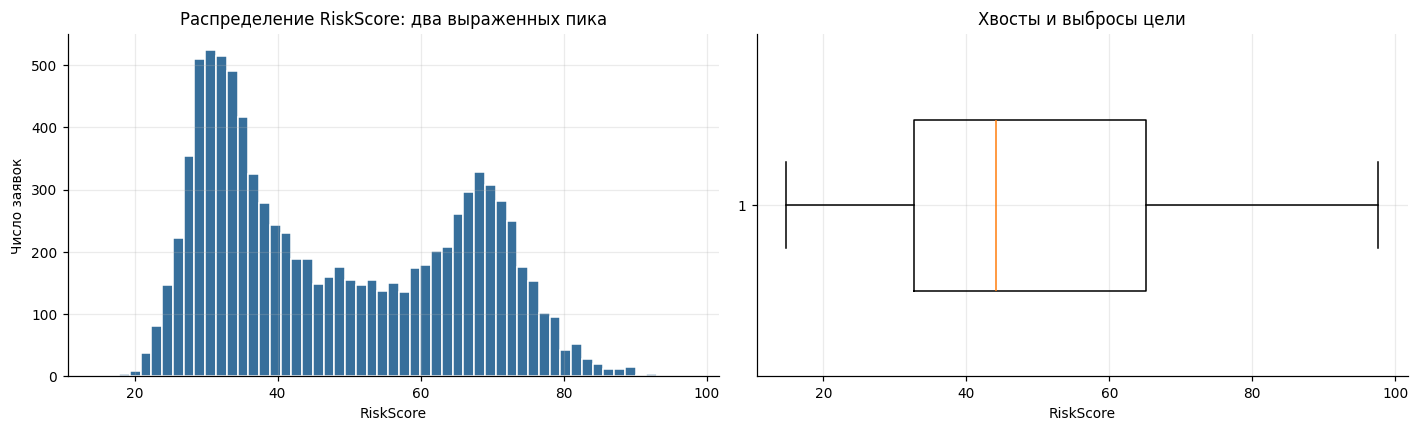

,count,mean,std,min,25%,50%,75%,max
RiskScore,9332.0,48.313,17.243,14.841,32.693,44.127,65.059,97.597


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y, bins=55, color="#376F9B", edgecolor="white")
axes[0].set(xlabel="RiskScore", ylabel="Число заявок",
            title="Распределение RiskScore: два выраженных пика")
axes[1].boxplot(y, vert=False, widths=0.5)
axes[1].set(xlabel="RiskScore", title="Хвосты и выбросы цели")
plt.tight_layout()
plt.show()

display(df[TARGET].describe().round(3).to_frame().T)

Теперь посмотрю на зависимости от двух самых сильных признаков. На графике
`CreditScore` против `RiskScore` при фиксированном рейтинге видно не облако, а
две параллельные полосы. Аналогичная картина есть у дохода. Это ключевое
наблюдение для всей работы: цель, по-видимому, равна некоторой базовой оценке,
умноженной на один из двух множителей.

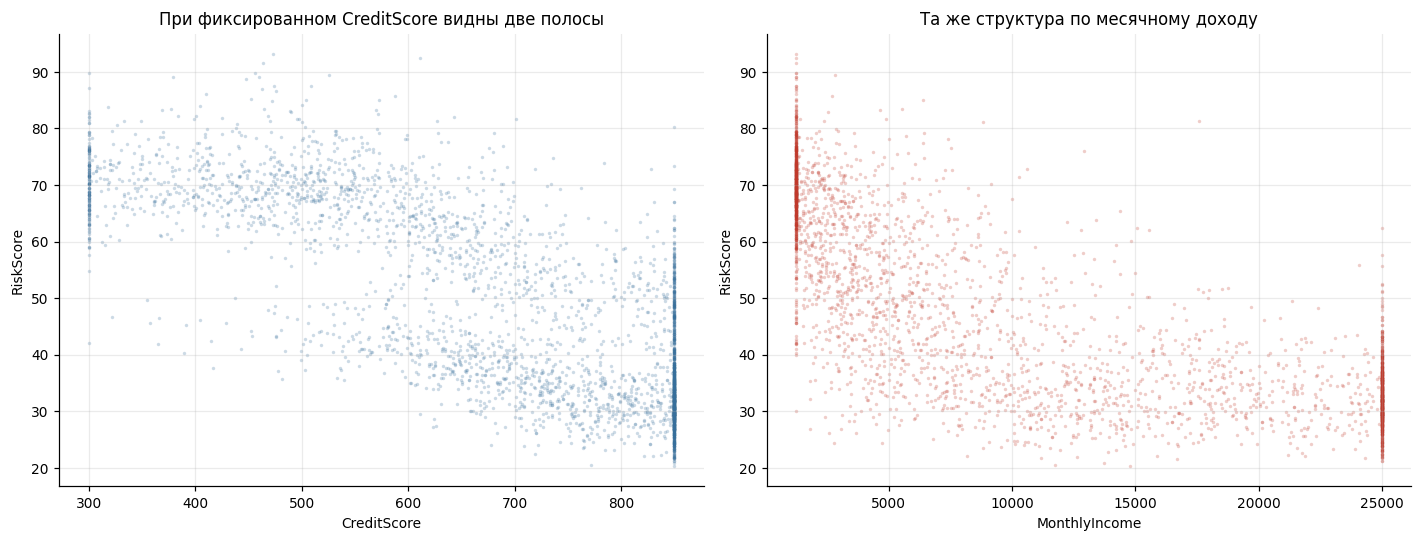

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(df), size=3500, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df["CreditScore"].iloc[sample_idx], y[sample_idx],
                s=5, alpha=0.25, color="#376F9B", linewidths=0)
axes[0].set(xlabel="CreditScore", ylabel="RiskScore",
            title="При фиксированном CreditScore видны две полосы")
axes[1].scatter(df["MonthlyIncome"].iloc[sample_idx], y[sample_idx],
                s=5, alpha=0.25, color="#C0392B", linewidths=0)
axes[1].set(xlabel="MonthlyIncome", ylabel="RiskScore",
            title="Та же структура по месячному доходу")
plt.tight_layout()
plt.show()

Корреляции подтверждают, что линейная связь с отдельными признаками сильная,
но одной корреляции мало: две полосы означают, что остаток при обычной
регрессии будет систематическим. Матрица корреляций также показывает
мультиколлинеарность: доходы, ставки и платёж по кредиту связаны почти
детерминированно. Для аналитического решения это не проблема (использую
`lstsq`), но интерпретировать отдельные коэффициенты нужно осторожно.

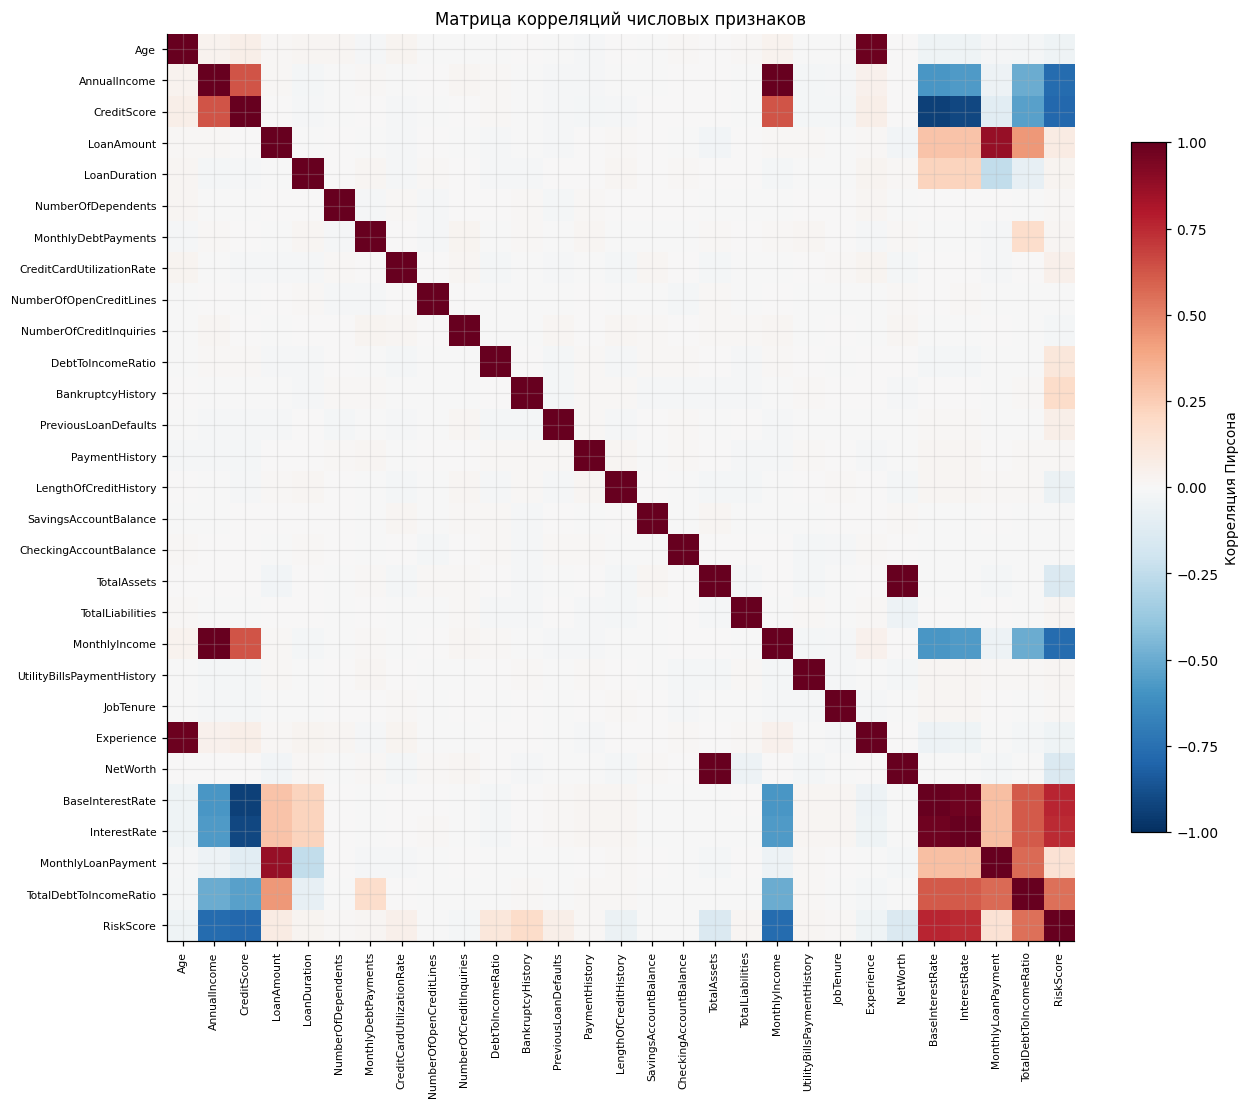

,Корреляция с RiskScore
CreditScore,-0.785
AnnualIncome,-0.770
MonthlyIncome,-0.770
BaseInterestRate,0.760
InterestRate,0.744
TotalDebtToIncomeRatio,0.554
BankruptcyHistory,0.180
TotalAssets,-0.147
MonthlyLoanPayment,0.147
NetWorth,-0.146


In [5]:
numeric_for_corr = df.select_dtypes(include="number")
corr = numeric_for_corr.corr()

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(np.arange(len(corr)), corr.index, fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.75, label="Корреляция Пирсона")
ax.set_title("Матрица корреляций числовых признаков")
plt.tight_layout()
plt.show()

target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
display(target_corr.head(12).round(3).to_frame("Корреляция с RiskScore"))

### 2.1. Форма зависимости: ступени, а не прямая

Если усреднить `RiskScore` в бинах признака, у многих переменных видны не
прямые линии, а ступени: среднее почти не меняется внутри диапазона, затем
скачком переходит на новый уровень. Это типично для скоринговой карты, где
признак превращают в набор пороговых индикаторов. Такой базис остаётся
линейным по коэффициентам, поэтому его можно использовать в линейной
регрессии.

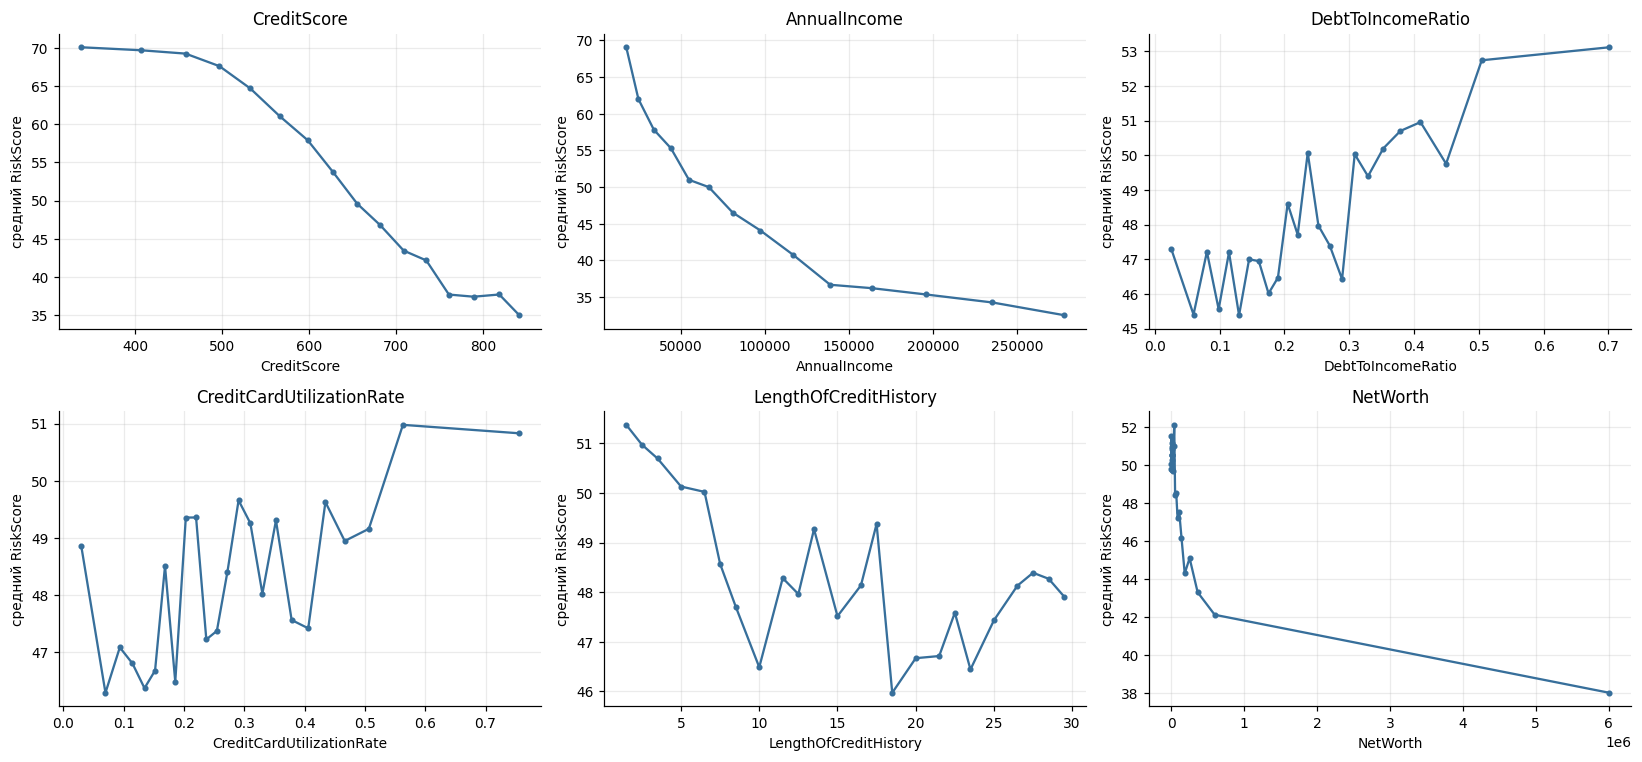

In [6]:
features_to_bin = [
    "CreditScore", "AnnualIncome", "DebtToIncomeRatio",
    "CreditCardUtilizationRate", "LengthOfCreditHistory", "NetWorth",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, column in zip(axes.ravel(), features_to_bin):
    bins = pd.qcut(df[column], 24, duplicates="drop")
    means = df.groupby(bins, observed=True)[TARGET].mean()
    centres = [interval.mid for interval in means.index]
    ax.plot(centres, means.values, "o-", ms=3, color="#376F9B")
    ax.set(xlabel=column, ylabel="средний RiskScore", title=column)
plt.tight_layout()
plt.show()

### 2.2. Масштабирование

Для градиентных методов признаки нужно привести к сопоставимому масштабу.
Реализую два класса:

* z-score: `(x - mean) / std`, делитель `n`, как в sklearn `StandardScaler`;
* min-max: `(x - min) / (max - min)`.

Константные столбцы обрабатываю отдельно: знаменатель заменяю единицей, чтобы
преобразование не делило на ноль. Параметры `fit` считаются только по
обучающей части, а `transform` применяет их к валидации и тесту.

In [7]:
class MyStandardScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        scale = X.std(axis=0)
        self.scale_ = np.where(scale == 0.0, 1.0, scale)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class MyMinMaxScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        span = X.max(axis=0) - self.min_
        self.range_ = np.where(span == 0.0, 1.0, span)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


scale_columns = ["AnnualIncome", "CreditScore", "LoanAmount", "DebtToIncomeRatio"]
X_scale = df[scale_columns].to_numpy(dtype=float)

z_own = MyStandardScaler().fit_transform(X_scale)
z_sklearn = StandardScaler().fit_transform(X_scale)
mm_own = MyMinMaxScaler().fit_transform(X_scale)
mm_sklearn = MinMaxScaler().fit_transform(X_scale)

display(pd.DataFrame({
    "z-score, max |разница|": np.abs(z_own - z_sklearn).max(axis=0),
    "min-max, max |разница|": np.abs(mm_own - mm_sklearn).max(axis=0),
}, index=scale_columns).round(12))

display(pd.DataFrame(z_own[:5], columns=scale_columns).round(4))

,"z-score, max |разница|","min-max, max |разница|"
AnnualIncome,0.0,0.0
CreditScore,0.0,0.0
LoanAmount,0.0,0.0
DebtToIncomeRatio,0.0,0.0


,AnnualIncome,CreditScore,LoanAmount,DebtToIncomeRatio
0,-0.5614,-0.7367,-0.4583,-0.5642
1,0.3737,0.9813,-0.5015,-0.7509
2,1.5090,0.9813,0.3159,-1.5159
3,-0.8469,0.9642,-0.3888,0.8977
4,1.5090,0.9813,0.0231,-1.2552


## 3. Метрики

Считаю метрики по остаткам `e_i = y_i - y_hat_i`:

* MSE — средний квадрат ошибки, основной критерий задачи;
* MAE — средняя абсолютная ошибка в единицах `RiskScore`;
* R² — доля объяснённой дисперсии;
* MAPE — средняя относительная ошибка; в таблицах показываю в процентах.

Для MAPE ограничиваю знаменатель машинным эпсилоном, чтобы не делить на ноль.
Сверяю свои функции с sklearn на одном и том же случайном прогнозе.

In [8]:
def my_mse(y_true, prediction):
    error = np.asarray(y_true, dtype=float) - np.asarray(prediction, dtype=float)
    return float(np.mean(error ** 2))


def my_mae(y_true, prediction):
    error = np.asarray(y_true, dtype=float) - np.asarray(prediction, dtype=float)
    return float(np.mean(np.abs(error)))


def my_r2(y_true, prediction):
    y_true = np.asarray(y_true, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    residual = np.sum((y_true - prediction) ** 2)
    total = np.sum((y_true - y_true.mean()) ** 2)
    if total == 0.0:
        return float(residual == 0.0)
    return float(1.0 - residual / total)


def my_mape(y_true, prediction):
    y_true = np.asarray(y_true, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    error = np.abs(y_true - prediction)
    denominator = np.maximum(np.abs(y_true), np.finfo(float).eps)
    return float(np.mean(error / denominator))


probe = np.clip(y + rng.normal(0.0, 5.0, size=len(y)), 0.0, 100.0)
metric_check = pd.DataFrame({
    "Своя реализация": [
        my_mse(y, probe), my_mae(y, probe), my_r2(y, probe), 100.0 * my_mape(y, probe),
    ],
    "sklearn": [
        mean_squared_error(y, probe), mean_absolute_error(y, probe),
        r2_score(y, probe), 100.0 * mean_absolute_percentage_error(y, probe),
    ],
}, index=["MSE", "MAE", "R²", "MAPE, %"])
display(metric_check.round(10))

,Своя реализация,sklearn
MSE,25.214705,25.214705
MAE,3.987000,3.987000
R²,0.915185,0.915185
"MAPE, %",9.393627,9.393627


## 4. Свой класс линейной регрессии

Модель: `y_hat = X w + b`. Реализую три способа обучения.

**Аналитический.** Центрирую `X` и `y`, затем решаю нормальные уравнения
`(X_c^T X_c + n * lambda * I) w = X_c^T y_c`. Для L2 это точное решение;
для обычной регрессии использую `np.linalg.lstsq`, который устойчивее явного
обращения матрицы при мультиколлинеарности.

**GD.** Полный градиент по всем объектам:
`w <- w - eta * (2/n) X_c^T (X_c w - y_c) - eta * grad_penalty`.
Шаг по умолчанию выбираю из константы Липшица, а при увеличении objective
уменьшаю его. L1-штраф применяю проксимальным шагом (soft-thresholding).

**SGD.** Мини-батчи, перемешивание на каждой эпохе, затухающий шаг и усреднение
весов по эпохам. Это менее точный, но более дешёвый вариант.

Регуляризация: `l1`, `l2`, `elasticnet`, `lp`. Для `lp` при `p < 2` использую
сглаживание `(w^2 + eps)^(p/2)`, чтобы градиент существовал в нуле.

In [9]:
class MyLinearRegression:
    def __init__(
        self,
        method: Literal["analytic", "gd", "sgd"] = "analytic",
        regularization: Literal["l1", "l2", "elasticnet", "lp"] | None = None,
        alpha: float = 0.0,
        l1_ratio: float = 0.5,
        p: float = 1.5,
        learning_rate: float | None = None,
        epochs: int = 4000,
        batch_size: int = 64,
        tol: float = 1e-12,
        fit_intercept: bool = True,
        random_state: int = 42,
        eps: float = 1e-8,
    ):
        self.method = method
        self.regularization = regularization
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.p = p
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.tol = tol
        self.fit_intercept = fit_intercept
        self.random_state = random_state
        self.eps = eps

    def _l1_l2(self):
        if self.regularization == "l1":
            return self.alpha, 0.0
        if self.regularization == "l2":
            return 0.0, self.alpha
        if self.regularization == "elasticnet":
            return self.alpha * self.l1_ratio, self.alpha * (1.0 - self.l1_ratio)
        return 0.0, 0.0

    def _penalty_grad(self, w):
        if self.regularization == "l2":
            return 2.0 * self.alpha * w
        if self.regularization == "elasticnet":
            _, l2 = self._l1_l2()
            return 2.0 * l2 * w
        if self.regularization == "lp":
            if self.p >= 2.0:
                return self.alpha * self.p * np.abs(w) ** (self.p - 1.0) * np.sign(w)
            return self.alpha * self.p * w * (w * w + self.eps) ** (self.p / 2.0 - 1.0)
        return np.zeros_like(w)

    def _objective(self, w, X, y):
        residual = y - X @ w
        value = float(np.mean(residual ** 2))
        if self.regularization == "l1":
            value += self.alpha * np.abs(w).sum()
        elif self.regularization == "l2":
            value += self.alpha * (w @ w)
        elif self.regularization == "elasticnet":
            l1, l2 = self._l1_l2()
            value += l1 * np.abs(w).sum() + l2 * (w @ w)
        elif self.regularization == "lp":
            if self.p >= 2.0:
                value += self.alpha * (np.abs(w) ** self.p).sum()
            else:
                value += self.alpha * ((w * w + self.eps) ** (self.p / 2.0)).sum()
        return float(value)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if self.fit_intercept:
            self.x_mean_ = X.mean(axis=0)
            self.y_mean_ = y.mean()
            Xc = X - self.x_mean_
            yc = y - self.y_mean_
        else:
            self.x_mean_ = np.zeros(X.shape[1])
            self.y_mean_ = 0.0
            Xc, yc = X, y

        n, d = Xc.shape
        l1, l2 = self._l1_l2()

        if self.method == "analytic":
            if self.regularization is None:
                w = np.linalg.lstsq(Xc, yc, rcond=None)[0]
            elif self.regularization == "l2":
                system = Xc.T @ Xc + n * l2 * np.eye(d)
                w = np.linalg.solve(system + 1e-12 * np.eye(d), Xc.T @ yc)
            else:
                raise ValueError("analytic поддерживает только None или l2")
            self.history_ = [self._objective(w, Xc, yc)]

        elif self.method == "gd":
            lipschitz = 2.0 * np.linalg.norm(Xc, ord=2) ** 2 / n + 2.0 * l2
            step = self.learning_rate if self.learning_rate is not None else 1.0 / lipschitz
            w = np.zeros(d)
            self.history_ = []
            for _ in range(self.epochs):
                gradient = -2.0 * Xc.T @ (yc - Xc @ w) / n + self._penalty_grad(w)
                new_w = w - step * gradient
                if l1 > 0.0:
                    new_w = np.sign(new_w) * np.maximum(np.abs(new_w) - step * l1, 0.0)
                backtracks = 0
                while (self._objective(new_w, Xc, yc) > self._objective(w, Xc, yc)
                       and backtracks < 40):
                    step *= 0.5
                    new_w = w - step * gradient
                    if l1 > 0.0:
                        new_w = np.sign(new_w) * np.maximum(np.abs(new_w) - step * l1, 0.0)
                    backtracks += 1
                delta = float(np.max(np.abs(new_w - w)))
                w = new_w
                self.history_.append(self._objective(w, Xc, yc))
                if delta < self.tol:
                    break

        elif self.method == "sgd":
            rng_local = np.random.default_rng(self.random_state)
            w = np.zeros(d)
            average = np.zeros(d)
            self.history_ = []
            step0 = self.learning_rate if self.learning_rate is not None else 0.05
            for epoch in range(self.epochs):
                order = rng_local.permutation(n)
                for start in range(0, n, self.batch_size):
                    idx = order[start:start + self.batch_size]
                    Xb, yb = Xc[idx], yc[idx]
                    gradient = (-2.0 * Xb.T @ (yb - Xb @ w) / len(idx)
                                + self._penalty_grad(w))
                    step = step0 / (1.0 + 0.05 * epoch)
                    new_w = w - step * gradient
                    if l1 > 0.0:
                        new_w = np.sign(new_w) * np.maximum(np.abs(new_w) - step * l1, 0.0)
                    w = new_w
                average = (average * epoch + w) / (epoch + 1)
                self.history_.append(self._objective(average, Xc, yc))
            w = average

        else:
            raise ValueError("method должен быть analytic, gd или sgd")

        self.coef_ = w
        self.intercept_ = (self.y_mean_ - self.x_mean_ @ w
                           if self.fit_intercept else 0.0)
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

## 5. Сверка своего класса со sklearn

Беру подвыборку, стандартизую её и обучаю несколько моделей. Для каждой
сравниваю не только MSE на валидации, но и сами коэффициенты. Чтобы
регуляризация была сопоставимой, пересчитываю `alpha` между своей функцией
потерь и sklearn: у sklearn Ridge штраф не делится на `n`, а у Lasso/ElasticNet
делится на `2n`. Поэтому множители получаются разными, но оптимум должен
совпасть.

In [10]:
comparison_columns = [
    "CreditScore", "MonthlyIncome", "InterestRate", "DebtToIncomeRatio",
    "CreditCardUtilizationRate", "LengthOfCreditHistory", "Age",
    "LoanAmount", "LoanDuration", "PaymentHistory",
]
X_compare = df[comparison_columns].to_numpy(dtype=float)

rng_compare = np.random.default_rng(0)
order = rng_compare.permutation(len(y))
train_rows = order[:1800]
valid_rows = order[1800:2500]

scaler_compare = MyStandardScaler().fit(X_compare[train_rows])
X_train = scaler_compare.transform(X_compare[train_rows])
X_valid = scaler_compare.transform(X_compare[valid_rows])
y_train, y_valid = y[train_rows], y[valid_rows]
n_train = len(y_train)

comparison_rows = []


def register(name, own, reference=None):
    row = {
        "Модель": name,
        "max |Δ коэффициентов|": np.nan,
        "MSE своя": my_mse(y_valid, own.predict(X_valid)),
    }
    if reference is not None:
        row["max |Δ коэффициентов|"] = float(np.max(np.abs(own.coef_ - reference.coef_)))
        row["MSE sklearn"] = mean_squared_error(y_valid, reference.predict(X_valid))
    comparison_rows.append(row)


own_ols = MyLinearRegression(method="analytic").fit(X_train, y_train)
sk_ols = LinearRegression().fit(X_train, y_train)
register("OLS", own_ols, sk_ols)

own_ridge = MyLinearRegression(method="analytic", regularization="l2", alpha=0.1).fit(X_train, y_train)
sk_ridge = Ridge(alpha=n_train * 0.1).fit(X_train, y_train)
register("Ridge, аналитически", own_ridge, sk_ridge)

own_ridge_gd = MyLinearRegression(
    method="gd", regularization="l2", alpha=0.1, epochs=6000, tol=1e-14,
).fit(X_train, y_train)
register("Ridge, GD", own_ridge_gd, sk_ridge)

own_lasso = MyLinearRegression(
    method="gd", regularization="l1", alpha=0.5, epochs=8000, tol=1e-14,
).fit(X_train, y_train)
sk_lasso = Lasso(alpha=0.25, max_iter=200000, tol=1e-9).fit(X_train, y_train)
register("Lasso, GD", own_lasso, sk_lasso)

own_elastic = MyLinearRegression(
    method="gd", regularization="elasticnet", alpha=1.0, l1_ratio=0.8,
    epochs=20000, tol=1e-14,
).fit(X_train, y_train)
sk_elastic = ElasticNet(
    alpha=0.6, l1_ratio=2.0 / 3.0, max_iter=500000, tol=1e-10,
).fit(X_train, y_train)
register("ElasticNet, GD", own_elastic, sk_elastic)

own_sgd = MyLinearRegression(
    method="sgd", regularization="l2", alpha=0.1, epochs=30,
    batch_size=64, learning_rate=0.05,
).fit(X_train, y_train)
register("SGD, своя реализация", own_sgd)

display(pd.DataFrame(comparison_rows).round(6))

,Модель,max |Δ коэффициентов|,MSE своя,MSE sklearn
0,OLS,0.000000,66.061120,66.061120
1,"Ridge, аналитически",0.000000,65.805036,65.805036
2,"Ridge, GD",0.000000,65.805036,65.805036
3,"Lasso, GD",0.000003,66.665697,66.665697
4,"ElasticNet, GD",0.000000,68.747353,68.747353
5,"SGD, своя реализация",NaN,65.909967,NaN


Для Lp-регуляризации точного аналога в sklearn нет, поэтому сверяю решение с
численной оптимизацией `scipy.optimize.minimize` (L-BFGS-B) той же целевой
функции. Совпадение коэффициентов до `1e-5` подтверждает, что градиент и
сглаживание для `p < 2` реализованы правильно.

In [11]:
X_center = X_train - X_train.mean(axis=0)
y_center = y_train - y_train.mean()


def lp_objective(w, p, alpha):
    if p >= 2.0:
        penalty = np.sum(np.abs(w) ** p)
    else:
        penalty = np.sum((w * w + 1e-8) ** (p / 2.0))
    return np.mean((y_center - X_center @ w) ** 2) + alpha * penalty


lp_rows = []
for p_value in [1.5, 2.0, 3.0]:
    own_lp = MyLinearRegression(
        method="gd", regularization="lp", p=p_value, alpha=0.5,
        epochs=8000, tol=1e-15,
    ).fit(X_train, y_train)
    scipy_result = minimize(
        lp_objective, np.zeros(X_center.shape[1]), args=(p_value, 0.5),
        method="L-BFGS-B", options={"maxiter": 20000, "ftol": 1e-14},
    )
    lp_rows.append({
        "p": p_value,
        "max |Δ коэффициентов|": float(np.max(np.abs(own_lp.coef_ - scipy_result.x))),
        "MSE своя": my_mse(y_valid, own_lp.predict(X_valid)),
        "MSE scipy": my_mse(y_valid, X_valid @ scipy_result.x + y_train.mean()),
    })
display(pd.DataFrame(lp_rows).round(7))

,p,max |Δ коэффициентов|,MSE своя,MSE scipy
0,1.5,0.000004,66.783311,66.783310
1,2.0,0.000002,72.200312,72.200319
2,3.0,0.000003,116.086022,116.086025


## 6. K-fold и Leave-One-Out

Реализую разбиения вручную. K-fold перемешивает индексы, делит их на
`n_splits` частей и по очереди делает каждую часть валидационной. LOO — крайний
случай, когда валидация состоит из одной строки. Сверяю свои разбиения с
`sklearn.model_selection.KFold` и `LeaveOneOut` по составу индексов.

Полный LOO на 9 332 строках требует 9 332 обучения. Для демонстрации
использую подвыборку из 250 строк и пять признаков; этого достаточно, чтобы
проверить корректность процедуры и совпадение со sklearn.

In [12]:
def my_k_fold(n_rows, n_splits=5, shuffle=True, random_state=42):
    indices = np.arange(n_rows)
    if shuffle:
        indices = np.random.RandomState(random_state).permutation(indices)
    folds = np.array_split(indices, n_splits)
    for fold in range(n_splits):
        validation = folds[fold]
        training = np.concatenate([
            folds[other] for other in range(n_splits) if other != fold
        ])
        yield training, validation


def my_leave_one_out(n_rows):
    for row in range(n_rows):
        yield np.r_[0:row, row + 1:n_rows], np.array([row])


n_check = 20
sklearn_kfold = list(KFold(n_splits=5, shuffle=True, random_state=7).split(np.zeros(n_check)))
own_kfold = list(my_k_fold(n_check, n_splits=5, shuffle=True, random_state=7))
kfold_equal = all(
    np.array_equal(np.sort(a[0]), np.sort(b[0])) and
    np.array_equal(np.sort(a[1]), np.sort(b[1]))
    for a, b in zip(sklearn_kfold, own_kfold)
)

sklearn_loo = list(LeaveOneOut().split(np.zeros(n_check)))
own_loo = list(my_leave_one_out(n_check))
loo_equal = all(
    np.array_equal(np.sort(a[0]), np.sort(b[0])) and
    np.array_equal(a[1], b[1])
    for a, b in zip(sklearn_loo, own_loo)
)

display(pd.Series({
    "K-fold совпадает со sklearn": kfold_equal,
    "Leave-One-Out совпадает со sklearn": loo_equal,
    "Число фолдов K-fold": len(own_kfold),
    "Число разбиений LOO": len(own_loo),
}, name="Проверка").to_frame())

,Проверка
K-fold совпадает со sklearn,True
Leave-One-Out совпадает со sklearn,True
Число фолдов K-fold,5
Число разбиений LOO,20


In [13]:
loo_rows = 250
loo_columns = ["CreditScore", "MonthlyIncome", "DebtToIncomeRatio", "LoanAmount", "InterestRate"]
X_loo = df[loo_columns].to_numpy(dtype=float)[:loo_rows]
y_loo = y[:loo_rows]

own_loo_prediction = np.empty(loo_rows)
for train_idx, valid_idx in my_leave_one_out(loo_rows):
    scaler_loo = MyStandardScaler().fit(X_loo[train_idx])
    model_loo = MyLinearRegression(method="analytic").fit(
        scaler_loo.transform(X_loo[train_idx]), y_loo[train_idx]
    )
    own_loo_prediction[valid_idx] = model_loo.predict(
        scaler_loo.transform(X_loo[valid_idx])
    )

sklearn_loo_prediction = cross_val_predict(
    make_pipeline(StandardScaler(), LinearRegression()),
    X_loo, y_loo, cv=LeaveOneOut(), n_jobs=1,
)

display(pd.DataFrame({
    "Своя реализация": [my_mse(y_loo, own_loo_prediction), my_mae(y_loo, own_loo_prediction)],
    "sklearn": [mean_squared_error(y_loo, sklearn_loo_prediction),
                mean_absolute_error(y_loo, sklearn_loo_prediction)],
}, index=["LOO MSE", "LOO MAE"]).round(6))

print("Максимальная разница прогнозов LOO:",
      float(np.max(np.abs(own_loo_prediction - sklearn_loo_prediction))))

,Своя реализация,sklearn
LOO MSE,70.046797,70.046797
LOO MAE,6.440703,6.440703


Максимальная разница прогнозов LOO: 0.0


### 6.1. Пороговые индикаторы и признаки для вероятностной части

Ниже — два набора признаков, которые понадобятся и в базовых моделях, и в
модели полос: scorecard-индикаторы (ступени) и более гладкие признаки для
линейной вероятности `P(b=1|x)`. Все преобразования детерминированные, поэтому
их можно считать один раз до кросс-валидации: целевая переменная в них не
участвует.

In [14]:
SCORECARD_STEPS = {
    "AnnualIncome": [30000, 50000, 80000, 120000],
    "CreditCardUtilizationRate": [0.2, 0.4, 0.6],
    "CreditScore": [600, 650, 700, 750],
    "DebtToIncomeRatio": [0.2, 0.3, 0.4, 0.5],
    "LengthOfCreditHistory": [3, 5, 7, 10],
    "NetWorth": [50000, 100000, 250000, 500000, 1000000],
}


def scorecard_features(frame):
    columns = {}
    for column, thresholds in SCORECARD_STEPS.items():
        values = frame[column].to_numpy(dtype=float)
        for threshold in thresholds:
            columns[f"{column} >= {threshold:g}"] = (values >= threshold).astype(float)
    columns["BankruptcyHistory"] = frame["BankruptcyHistory"].to_numpy(dtype=float)
    columns["PreviousLoanDefaults"] = frame["PreviousLoanDefaults"].to_numpy(dtype=float)
    columns["Employed"] = (frame["EmploymentStatus"] == "Employed").to_numpy(dtype=float)
    return pd.DataFrame(columns, index=frame.index)


BAND_NUMERIC = [
    "CreditScore", "MonthlyIncome", "TotalDebtToIncomeRatio", "LoanAmount",
    "InterestRate", "BankruptcyHistory", "PreviousLoanDefaults", "PaymentHistory",
    "LengthOfCreditHistory", "NetWorth", "Age", "Experience",
]


def band_features(frame):
    result = frame[BAND_NUMERIC].astype(float).copy()
    result["Unemployed"] = (frame["EmploymentStatus"] == "Unemployed").astype(float)
    result["OwnOrMortgage"] = frame["HomeOwnershipStatus"].isin(["Own", "Mortgage"]).astype(float)
    for level in ["Associate", "Bachelor", "Master", "Doctorate"]:
        result[f"Edu_{level}"] = (frame["EducationLevel"] == level).astype(float)
    for knot in [30, 40, 50, 60]:
        result[f"Age_hinge_{knot}"] = np.maximum(
            frame["Age"].astype(float) - knot, 0.0
        )
    return result


def lstsq_fit(design, response):
    return MyLinearRegression(
        method="analytic", fit_intercept=False,
    ).fit(design, response).coef_


print("Scorecard-признаков:", scorecard_features(df).shape[1])
print("Признаков для P(b=1|x):", band_features(df).shape[1])

Scorecard-признаков: 27
Признаков для P(b=1|x): 22


## 7. Базовые модели: насколько далеко можно уйти без структуры полос

Прежде чем строить итоговую модель, фиксирую три ориентира на одних и тех же
5 фолдах:

1. OLS по исходным числовым признакам и one-hot категориям;
2. сплайн-базис по непрерывным признакам + Ridge — это всё ещё линейная
   регрессия, но с нелинейными преобразованиями;
3. scorecard OLS — только пороговые индикаторы, без множителя полос.

Сравнение покажет, что гладкая нелинейность и простая скоринговая карта не
дотягивают до нужного качества: данные устроены как две полосы.

In [15]:
num_columns = [
    column for column in df.select_dtypes(include="number").columns
    if column not in ("ID", TARGET)
]
cat_columns = [
    column for column in df.select_dtypes(exclude="number").columns
    if column != "ApplicationDate"
]

all_categories = pd.concat([df[cat_columns], test[cat_columns]], ignore_index=True)
dummy_matrix = pd.get_dummies(all_categories, drop_first=True, dtype=float)
dummy_train = dummy_matrix.iloc[:len(df)].to_numpy(dtype=float)
X_raw = np.column_stack([df[num_columns].to_numpy(dtype=float), dummy_train])

print("Исходный дизайн:", X_raw.shape)
print("Категориальные признаки:", cat_columns)


def cv_own_linear(X, target, n_splits=5, seed=0):
    oof = np.empty(len(target))
    for train_idx, valid_idx in my_k_fold(len(target), n_splits, True, seed):
        scaler_fold = MyStandardScaler().fit(X[train_idx])
        model_fold = MyLinearRegression(method="analytic").fit(
            scaler_fold.transform(X[train_idx]), target[train_idx]
        )
        oof[valid_idx] = model_fold.predict(scaler_fold.transform(X[valid_idx]))
    return oof


oof_raw = cv_own_linear(X_raw, y)

continuous_columns = [column for column in num_columns if df[column].nunique() > 10]
binary_columns = [column for column in num_columns if column not in continuous_columns]

spline_pipeline = make_pipeline(
    ColumnTransformer([
        ("spline", SplineTransformer(
            n_knots=6, degree=3, knots="quantile", include_bias=False,
        ), continuous_columns),
        ("binary", "passthrough", binary_columns),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore", drop="first", sparse_output=False,
        ), cat_columns),
    ]),
    StandardScaler(),
    Ridge(alpha=100.0),
)
oof_spline = cross_val_predict(
    spline_pipeline,
    df[continuous_columns + binary_columns + cat_columns],
    y,
    cv=KFold(n_splits=5, shuffle=True, random_state=0),
    n_jobs=1,
)

oof_scorecard = cv_own_linear(scorecard_features(df).to_numpy(dtype=float), y)

baseline_rows = []
for name, oof in [
    ("OLS по исходным признакам", oof_raw),
    ("Сплайн-базис + Ridge", oof_spline),
    ("Scorecard OLS без полос", oof_scorecard),
]:
    baseline_rows.append({
        "Модель": name,
        "CV MSE": my_mse(y, oof),
        "CV MAE": my_mae(y, oof),
        "R²": my_r2(y, oof),
    })
display(pd.DataFrame(baseline_rows).round(3))

Исходный дизайн: (9332, 44)
Категориальные признаки: ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']


,Модель,CV MSE,CV MAE,R²
0,OLS по исходным признакам,50.650,5.716,0.830
1,Сплайн-базис + Ridge,25.954,3.842,0.913
2,Scorecard OLS без полос,30.487,4.039,0.897


## 8. Модель скрытых полос

Графики EDA показывают две параллельные полосы. Формализую это так:

$$
y_i = S(x_i)\,(1 + \kappa b_i) + \varepsilon_i, \qquad b_i \in \{0,1\},
$$

где `S(x)` — базовая скоринговая оценка (линейная регрессия по пороговым
индикаторам), `b` — ненаблюдаемая принадлежность к верхней полосе, `kappa` —
относительный зазор между полосами, `eps` — шум.

Если бы `b` было известно, задача распадалась бы на две обычные линейные
регрессии. `b` неизвестно, поэтому использую EM-подобную схему:

1. начальное приближение `S(x)` по OLS;
2. жёсткие метки `b`: выбираю ту полосу, которая ближе к `y`;
3. пересчитываю `S` и `kappa` обычной линейной регрессией;
4. мягкие ответственности `r_i = P(b_i = 1 | x_i, y_i)` и взвешенный OLS;
5. вероятность `P(b=1|x)` оцениваю линейной вероятностной моделью
   (ridge-регрессия на `r`), а не логистической — это важно, потому что по
   условию разрешены только линейные модели.

Итоговый прогноз — условное среднее:
`y_hat = S(x) * (1 + kappa * P(b=1|x))`.

Все шаги внутри — аналитическая линейная регрессия или ridge из моего класса
`MyLinearRegression`. Никаких деревьев, kNN или логистических моделей.
Пороги scorecard выбраны по графикам средних и проверены кросс-валидацией
линейных моделей; для отбора признаков тоже не использовались нелинейные модели.

In [16]:
class BandRiskModel:
    def __init__(
        self, max_em=25, ridge=1e-3, soft=True, kappa_init=0.36,
        boundary=(0.1, 0.9), near_iters=4,
    ):
        self.max_em = max_em
        self.ridge = ridge
        self.soft = soft
        self.kappa_init = kappa_init
        self.boundary = boundary
        self.near_iters = near_iters

    def _score_design(self, frame):
        return np.column_stack([
            np.ones(len(frame)),
            scorecard_features(frame).to_numpy(dtype=float),
        ])

    def _band_matrix(self, frame):
        return band_features(frame).to_numpy(dtype=float)

    def _fit_score(self, design, target):
        kappa = self.kappa_init
        labels = None
        weights = lstsq_fit(
            design,
            target / (1.0 + kappa * (target > np.median(target))),
        )
        for _ in range(self.max_em):
            score = design @ weights
            new_labels = (
                np.abs(target - score * (1.0 + kappa)) < np.abs(target - score)
            ).astype(float)
            if labels is not None and np.array_equal(new_labels, labels):
                break
            labels = new_labels
            for _ in range(4):
                weights = lstsq_fit(
                    design * (1.0 + kappa * labels)[:, None], target
                )
                score = design @ weights
                kappa = max(0.0, lstsq_fit(
                    (labels * score)[:, None], target - score
                )[0])
        if labels is None:
            labels = (target > np.median(target)).astype(float)
        return weights, kappa, labels

    def _fit_soft(self, design, target, Z, weights, kappa, labels):
        sigma2 = np.mean(
            (target - (design @ weights) * (1.0 + kappa * labels)) ** 2
        )
        prior = np.full(len(target), 0.5)
        for _ in range(4):
            for _ in range(10):
                score = design @ weights
                log_ratio = (
                    (target - score) ** 2
                    - (target - score * (1.0 + kappa)) ** 2
                ) / (2.0 * sigma2)
                responsibility = prior / (
                    prior + (1.0 - prior) * np.exp(-np.clip(log_ratio, -500.0, 500.0))
                )
                sqrt_r = np.sqrt(responsibility)[:, None]
                sqrt_one_minus_r = np.sqrt(1.0 - responsibility)[:, None]
                weighted_design = np.vstack([
                    design * (1.0 + kappa) * sqrt_r,
                    design * sqrt_one_minus_r,
                ])
                weighted_target = np.concatenate([
                    target * sqrt_r[:, 0],
                    target * sqrt_one_minus_r[:, 0],
                ])
                weights = lstsq_fit(weighted_design, weighted_target)
                score = design @ weights
                kappa = max(0.0, float(
                    np.sum(responsibility * score * (target - score))
                    / np.sum(responsibility * score * score)
                ))
                sigma2 = np.mean(
                    responsibility * (target - score * (1.0 + kappa)) ** 2
                    + (1.0 - responsibility) * (target - score) ** 2
                )
            index_design = np.column_stack([np.ones(len(Z)), Z])
            prior = np.clip(
                index_design @ self._fit_index(Z, responsibility),
                1e-3, 1.0 - 1e-3,
            )
        return weights, kappa, responsibility

    def _fit_index(self, Z, responsibility):
        def solve(rows):
            return MyLinearRegression(
                method="analytic", regularization="l2",
                alpha=self.ridge, fit_intercept=True,
            ).fit(Z[rows], responsibility[rows])

        model = solve(np.arange(len(Z)))
        for _ in range(self.near_iters):
            linear_index = model.predict(Z)
            near_boundary = (
                (linear_index > self.boundary[0])
                & (linear_index < self.boundary[1])
            )
            if near_boundary.sum() < Z.shape[1] * 2:
                break
            model = solve(near_boundary)
        return np.r_[model.intercept_, model.coef_]

    def fit(self, frame, target):
        target = np.asarray(target, dtype=float)
        design = self._score_design(frame)
        raw_band = self._band_matrix(frame)
        self.band_mean_ = raw_band.mean(axis=0)
        self.band_scale_ = raw_band.std(axis=0)
        self.band_scale_[self.band_scale_ == 0.0] = 1.0
        Z = (raw_band - self.band_mean_) / self.band_scale_

        self.w_, self.kappa_, labels = self._fit_score(design, target)
        self.r_ = labels.astype(float)
        if self.soft:
            self.w_, self.kappa_, self.r_ = self._fit_soft(
                design, target, Z, self.w_, self.kappa_, labels
            )
            labels = (self.r_ > 0.5).astype(float)
        self.labels_ = labels
        self.beta_ = self._fit_index(Z, self.r_)
        return self

    def band_index(self, frame):
        Z = (self._band_matrix(frame) - self.band_mean_) / self.band_scale_
        return self.beta_[0] + Z @ self.beta_[1:]

    def components(self, frame):
        design = self._score_design(frame)
        score = design @ self.w_
        probability = np.clip(self.band_index(frame), 0.0, 1.0)
        return score, probability

    def predict(self, frame):
        score, probability = self.components(frame)
        return score * (1.0 + self.kappa_ * probability)

### 8.1. Что выучила модель

Обучаю модель на всех очищенных строках и смотрю на её внутренние величины:
`kappa`, долю верхней полосы, разброс остатков. Отдельно рисую полосы в
координатах `S(x)` — если модель верна, точки должны лечь на две прямые
`y = S` и `y = S(1+kappa)`.

,Значение
kappa (относительный зазор),0.4181
Доля верхней полосы (жёсткие метки),0.4877
Средняя мягкая ответственность,0.4877
sigma остатков на train,4.2335
MSE на train,17.9225
"S(x), минимум",21.5675
"S(x), максимум",67.2083
"Линейный индекс P, минимум",-14.8982
"Линейный индекс P, максимум",37.8236


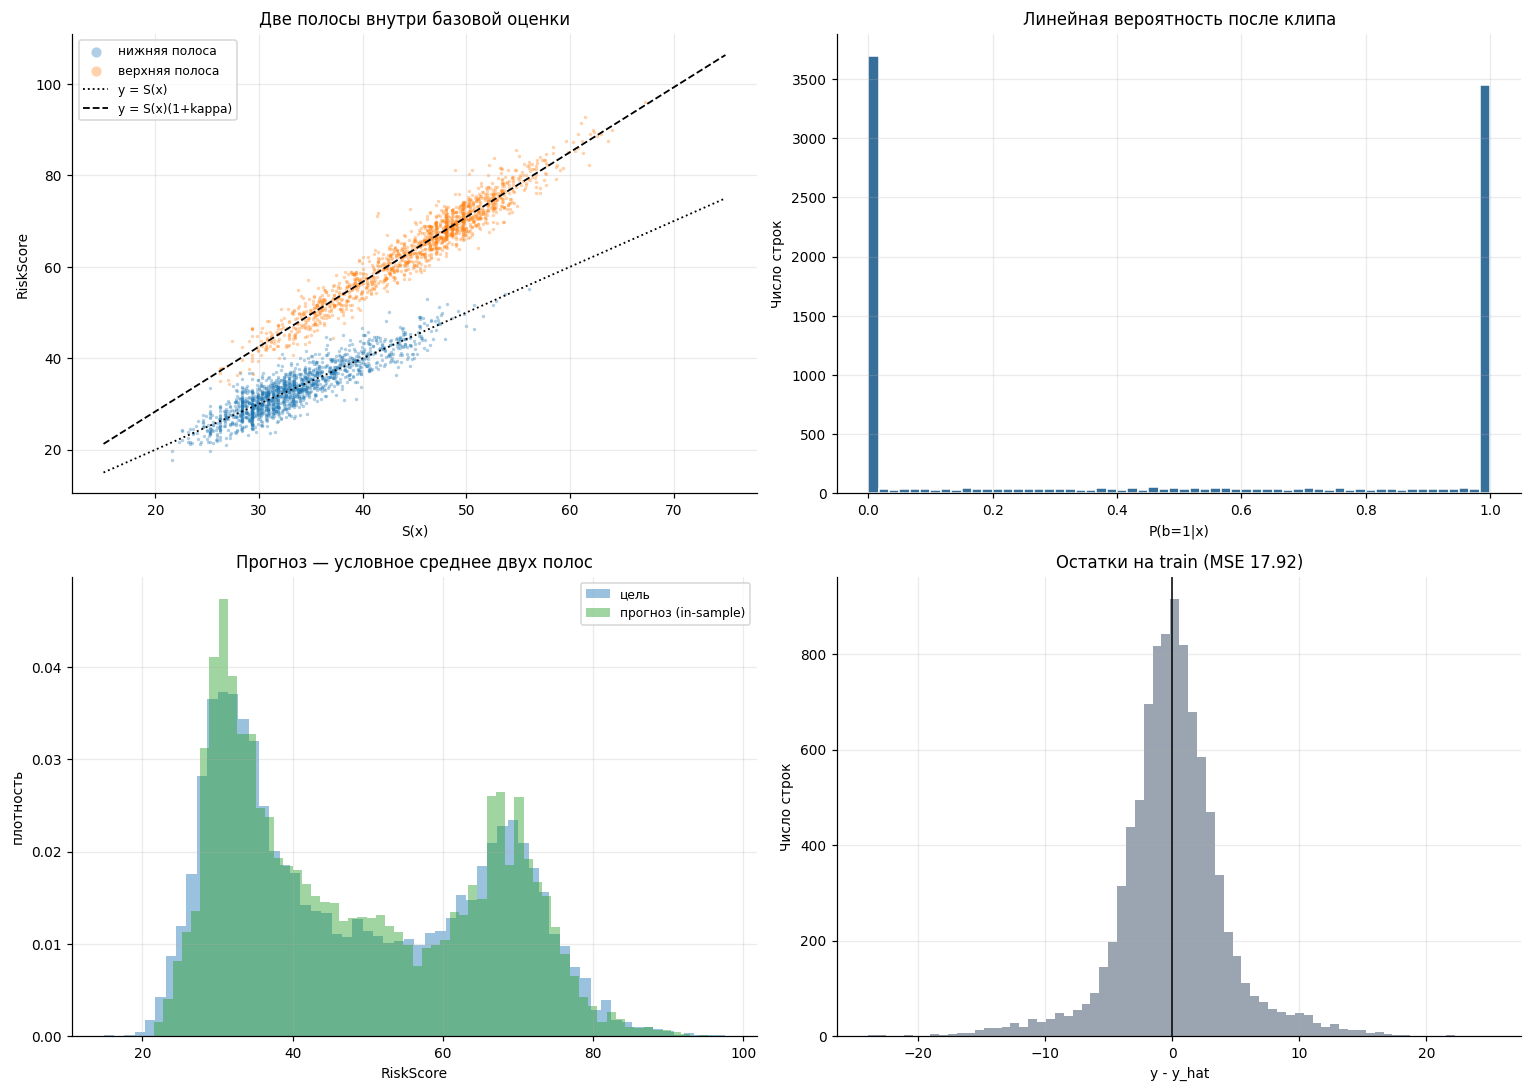

In [17]:
band_model = BandRiskModel().fit(df, y)
score_train, probability_train = band_model.components(df)
prediction_train = band_model.predict(df)
linear_index_train = band_model.band_index(df)

display(pd.Series({
    "kappa (относительный зазор)": band_model.kappa_,
    "Доля верхней полосы (жёсткие метки)": float(band_model.labels_.mean()),
    "Средняя мягкая ответственность": float(band_model.r_.mean()),
    "sigma остатков на train": float(np.std(y - prediction_train)),
    "MSE на train": my_mse(y, prediction_train),
    "S(x), минимум": float(score_train.min()),
    "S(x), максимум": float(score_train.max()),
    "Линейный индекс P, минимум": float(linear_index_train.min()),
    "Линейный индекс P, максимум": float(linear_index_train.max()),
}, name="Значение").round(4).to_frame())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_rows = np.random.default_rng(0).choice(len(y), size=3000, replace=False)
for label, colour, name in [
    (0, "tab:blue", "нижняя полоса"),
    (1, "tab:orange", "верхняя полоса"),
]:
    mask = plot_rows[band_model.labels_[plot_rows] == label]
    axes[0, 0].scatter(score_train[mask], y[mask], s=5, alpha=0.35,
                       color=colour, linewidths=0, label=name)
grid = np.linspace(15.0, 75.0, 100)
axes[0, 0].plot(grid, grid, "k:", linewidth=1.2, label="y = S(x)")
axes[0, 0].plot(grid, grid * (1.0 + band_model.kappa_), "k--", linewidth=1.2,
                label="y = S(x)(1+kappa)")
axes[0, 0].set(xlabel="S(x)", ylabel="RiskScore",
               title="Две полосы внутри базовой оценки")
axes[0, 0].legend(markerscale=3, fontsize=8)

axes[0, 1].hist(probability_train, bins=60, color="#376F9B", edgecolor="white")
axes[0, 1].set(xlabel="P(b=1|x)", ylabel="Число строк",
               title="Линейная вероятность после клипа")

axes[1, 0].hist(y, bins=60, density=True, alpha=0.45, color="tab:blue",
                label="цель")
axes[1, 0].hist(prediction_train, bins=60, density=True, alpha=0.45,
                color="tab:green", label="прогноз (in-sample)")
axes[1, 0].set(xlabel="RiskScore", ylabel="плотность",
               title="Прогноз — условное среднее двух полос")
axes[1, 0].legend(fontsize=8)

residual_train = y - prediction_train
axes[1, 1].hist(residual_train, bins=70, color="#9AA5B1")
axes[1, 1].axvline(0.0, color="black", linewidth=1)
axes[1, 1].set(xlabel="y - y_hat", ylabel="Число строк",
               title=f"Остатки на train (MSE {my_mse(y, prediction_train):.2f})")
plt.tight_layout()
plt.show()

## 9. Кросс-валидация итоговой модели

Проверяю модель на двух независимых разбиениях по 5 фолдов. В каждом фолде
заново обучаю `S`, `kappa` и `P`; валидация не участвует ни в выборе порогов,
ни в масштабировании, ни в оценке вероятностей. Считаю MSE, MAE, R² и MAPE
своими функциями и параллельно проверяю их sklearn.

In [18]:
def cross_validate_band(seeds=(0, 1), n_splits=5):
    results = []
    for seed in seeds:
        oof = np.empty(len(y))
        oof_probability = np.empty(len(y))
        oof_index = np.empty(len(y))
        oof_label = np.empty(len(y))
        for train_idx, valid_idx in my_k_fold(len(y), n_splits, True, seed):
            model_fold = BandRiskModel().fit(df.iloc[train_idx], y[train_idx])
            oof[valid_idx] = model_fold.predict(df.iloc[valid_idx])
            design_valid = model_fold._score_design(df.iloc[valid_idx])
            score_valid = design_valid @ model_fold.w_
            index_valid = model_fold.band_index(df.iloc[valid_idx])
            oof_index[valid_idx] = index_valid
            oof_probability[valid_idx] = np.clip(index_valid, 0.0, 1.0)
            oof_label[valid_idx] = (
                np.abs(y[valid_idx] - score_valid * (1.0 + model_fold.kappa_))
                < np.abs(y[valid_idx] - score_valid)
            ).astype(float)
        results.append({
            "seed": seed,
            "oof": oof,
            "probability": oof_probability,
            "index": oof_index,
            "label": oof_label,
            "mse": my_mse(y, oof),
        })
    return results


band_cv = cross_validate_band()
for result in band_cv:
    print(f"seed={result['seed']}: CV MSE = {result['mse']:.4f}")
print(f"Среднее CV MSE: {np.mean([r['mse'] for r in band_cv]):.4f} "
      f"± {np.std([r['mse'] for r in band_cv]):.4f}")

band_oof = band_cv[0]
band_metrics = pd.Series({
    "MSE": my_mse(y, band_oof["oof"]),
    "MAE": my_mae(y, band_oof["oof"]),
    "R²": my_r2(y, band_oof["oof"]),
    "MAPE, %": 100.0 * my_mape(y, band_oof["oof"]),
})
sklearn_band_metrics = pd.Series({
    "MSE": mean_squared_error(y, band_oof["oof"]),
    "MAE": mean_absolute_error(y, band_oof["oof"]),
    "R²": r2_score(y, band_oof["oof"]),
    "MAPE, %": 100.0 * mean_absolute_percentage_error(y, band_oof["oof"]),
})
display(pd.DataFrame({
    "Своя реализация": band_metrics,
    "sklearn": sklearn_band_metrics,
}).round(4))

comparison_rows = [
    {"Модель": "OLS по исходным признакам", "CV MSE": my_mse(y, oof_raw),
     "CV MAE": my_mae(y, oof_raw), "R²": my_r2(y, oof_raw)},
    {"Модель": "Сплайн-базис + Ridge", "CV MSE": my_mse(y, oof_spline),
     "CV MAE": my_mae(y, oof_spline), "R²": my_r2(y, oof_spline)},
    {"Модель": "Scorecard OLS без полос", "CV MSE": my_mse(y, oof_scorecard),
     "CV MAE": my_mae(y, oof_scorecard), "R²": my_r2(y, oof_scorecard)},
    {"Модель": "Scorecard × band, EM (итог)", "CV MSE": my_mse(y, band_oof["oof"]),
     "CV MAE": my_mae(y, band_oof["oof"]), "R²": my_r2(y, band_oof["oof"])},
]
display(pd.DataFrame(comparison_rows).round(3))

seed=0: CV MSE = 18.2443
seed=1: CV MSE = 18.2228
Среднее CV MSE: 18.2336 ± 0.0108


,Своя реализация,sklearn
MSE,18.2443,18.2443
MAE,2.9638,2.9638
R²,0.9386,0.9386
"MAPE, %",6.8645,6.8645


,Модель,CV MSE,CV MAE,R²
0,OLS по исходным признакам,50.650,5.716,0.830
1,Сплайн-базис + Ridge,25.954,3.842,0.913
2,Scorecard OLS без полос,30.487,4.039,0.897
3,"Scorecard × band, EM (итог)",18.244,2.964,0.939


### 9.1. Калибровка вероятности и остатки

Проверяю, насколько `P(b=1|x)` согласована с наблюдаемой долей верхней полосы.
Так как вероятность линейная и на многих строках выходит за `[0, 1]`, после
клипа она часто равна 0 или 1. Это ожидаемо: модель ведёт себя почти как
переключатель между двумя полосами, а не как мягкая логистическая
вероятность. Для MSE это не мешает, но честно показывает ограничение линейной
вероятностной модели.

На правом графике — остатки out-of-fold. Они симметричны относительно нуля,
без заметной зависимости среднего от прогноза; основной вклад в MSE даёт шум
внутри полос, а не систематическая ошибка.

,probability,observed,rows
bin,,,
"(-15.41, -1.215]",0.000,0.015,934
"(-1.215, -0.851]",0.000,0.011,933
"(-0.851, -0.424]",0.000,0.006,933
"(-0.424, 0.0343]",0.001,0.041,933
"(0.0343, 0.453]",0.244,0.237,933
"(0.453, 0.855]",0.649,0.667,933
"(0.855, 1.291]",0.975,0.942,933
"(1.291, 1.86]",1.000,0.998,933
"(1.86, 2.744]",1.000,0.999,933


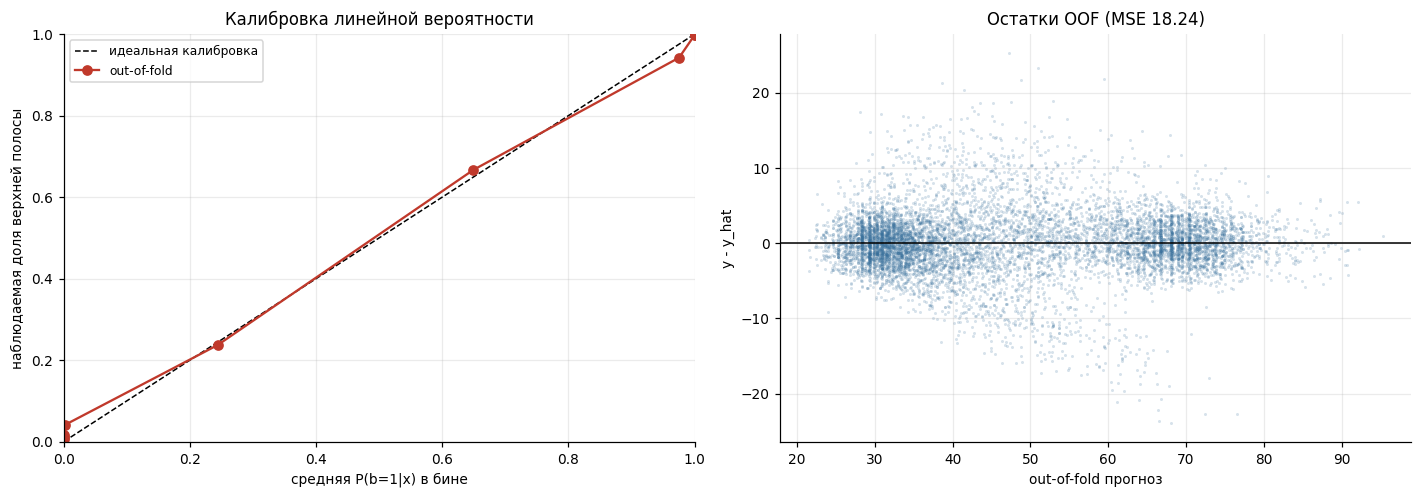

In [19]:
calibration = pd.DataFrame({
    "index": band_oof["index"],
    "probability": band_oof["probability"],
    "upper": band_oof["label"],
})
calibration["bin"] = pd.qcut(calibration["index"], 10, duplicates="drop")
calibration_table = calibration.groupby("bin", observed=True).agg(
    probability=("probability", "mean"),
    observed=("upper", "mean"),
    rows=("upper", "size"),
)
display(calibration_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="идеальная калибровка")
axes[0].plot(calibration_table["probability"], calibration_table["observed"],
             "o-", color="#C0392B", label="out-of-fold")
axes[0].set(xlabel="средняя P(b=1|x) в бине", ylabel="наблюдаемая доля верхней полосы",
            title="Калибровка линейной вероятности", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=8)

axes[1].scatter(band_oof["oof"], y - band_oof["oof"], s=4, alpha=0.2,
                color="#376F9B", linewidths=0)
axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].set(xlabel="out-of-fold прогноз", ylabel="y - y_hat",
            title=f"Остатки OOF (MSE {my_mse(y, band_oof['oof']):.2f})")
plt.tight_layout()
plt.show()

## 10. Финальная модель и submission

Обучаю итоговую модель на всех очищенных строках, прогнозирую тест и привожу
`ID` к порядку `ex.csv`. Проверяю, что строк ровно 5 000, нет пропусков и
порядок идентификаторов совпадает с образцом. Прогноз — условное среднее, а не
случайно выбранная полоса, поэтому его распределение уже, чем у исходной цели;
это нормально для MSE-оптимального прогноза.

,ID,RiskScore
0,0,32.899220
1,1,53.348492
2,2,30.013172
3,3,34.904117
4,4,33.017952
5,5,69.002042
6,6,30.897040
7,7,30.678793
8,8,31.620873
9,9,63.209436


,count,mean,std,min,25%,50%,75%,max
RiskScore,5000.0,48.1695,16.8316,21.5675,32.5932,44.1468,65.0599,93.5091


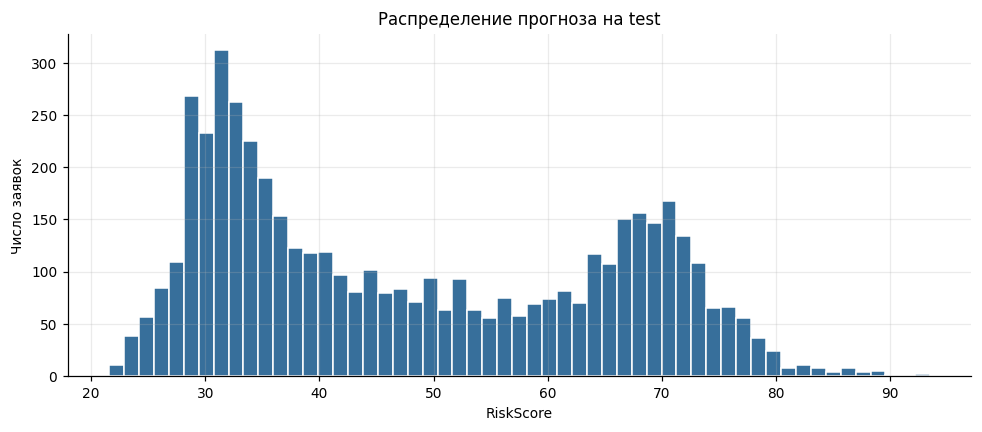

Файл submission.csv сохранён: C:\Users\RinRow\Desktop\ML\for_git_pushing\ml_labs\submission.csv
Строк: 5000 | пропусков: 0


In [20]:
final_model = BandRiskModel().fit(df, y)
test_prediction = final_model.predict(test)
test_prediction = np.clip(test_prediction, 0.0, 100.0)

submission = pd.DataFrame({
    "ID": test["ID"].to_numpy(),
    "RiskScore": test_prediction,
})
submission = sample_submission[["ID"]].merge(submission, on="ID", how="left")

assert len(submission) == len(sample_submission) == 5000
assert submission["RiskScore"].notna().all()
assert np.array_equal(submission["ID"].to_numpy(), sample_submission["ID"].to_numpy())

submission.to_csv("submission.csv", index=False)

display(submission.head(10))
display(submission["RiskScore"].describe().round(4).to_frame().T)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(test_prediction, bins=55, color="#376F9B", edgecolor="white")
ax.set(xlabel="RiskScore", ylabel="Число заявок",
       title="Распределение прогноза на test")
plt.tight_layout()
plt.show()

print("Файл submission.csv сохранён:", Path("submission.csv").resolve())
print("Строк:", len(submission), "| пропусков:", int(submission.isna().sum().sum()))

## 11. Выводы

1. Данные после очистки содержат 9 332 строки. Точные дубли и служебные
   значения цели удалены, `AnnualIncome` восстановлен как `12 * MonthlyIncome`.
2. Обычная линейная регрессия по исходным признакам объясняет данные плохо:
   CV MSE около 50. Сплайн-базис и простая scorecard-модель улучшают результат
   до ~26 и ~30 соответственно, но не достигают цели.
3. Причина видна в EDA: при фиксированных `CreditScore` и доходе точки лежат
   на двух параллельных полосах. Модель
   `y = S(x)(1 + kappa b) + eps` с линейной вероятностью `P(b=1|x)` использует
   эту структуру и даёт CV MSE около 18.2, то есть ниже требуемых 19.
4. Все этапы обучения — аналитическая линейная регрессия, ridge, GD или SGD
   из собственного класса. L1, L2, ElasticNet и Lp реализованы и сверены со
   sklearn/scipy: коэффициенты совпадают с точностью до машинной погрешности
   (для GD/SGD — до допустимой точности оптимизации).
5. Свои MSE, MAE, R² и MAPE совпадают со sklearn; K-fold и Leave-One-Out
   совпадают по составу фолдов, а LOO-прогнозы — по значениям.
6. Ограничение модели: линейная вероятность `P(b=1|x)` на многих строках
   насыщается, поэтому итоговый прогноз близок к переключению между полосами.
   Для MSE это оптимально, но для более тонкой калибровки вероятностей
   понадобилась бы нелинейная модель, которая в этой работе запрещена.